# TAHAP 2b (opsional) - KOREKSI ROI MANUAL (BKPM Acara 15)

Menampilkan gambar berstatus `perlu_cek` / `cadangan_roi` satu per satu, per kelas. Tandai **kotak ROI yang mengelilingi SEMUA objek kelasnya** (mis. semua orang), lalu tekan **ENTER/SPASI**.

- Tidak ingin menandai gambar itu: tekan **ESC** (atau ENTER tanpa kotak). Sel akan bertanya `Enter = lewati, q = berhenti`.
- ROI disimpan di `<proyek>/roi_manual.csv` setiap selesai satu gambar, jadi aman bila dihentikan di tengah.
- Setelah selesai, jalankan ulang notebook **02_segmentasi**: pada gambar ber-ROI, area di luar ROI dipakai sebagai referensi latar dan hasil dibatasi di dalam ROI.

**Penting:** jendela `cv2.selectROI` hanya muncul bila Jupyter berjalan di komputermu sendiri (VS Code lokal). Di Colab atau server tanpa layar, pakai **bagian 7** (isi koordinat lewat teks).

## 1. Setup dan import

In [1]:
import sys, os
from pathlib import Path

SCRIPTS = Path.cwd().resolve().parent / "scripts"
if not SCRIPTS.is_dir():
    SCRIPTS = Path.cwd().resolve()
sys.path.insert(0, str(SCRIPTS))

# Opsional: bila folder proyek bukan induk dari scripts/, hilangkan tanda # dan isi path-nya
# os.environ["PROYEK_ROOT"] = r"D:\rompi-cerdas-fin"

import cv2
import numpy as np
from IPython.display import Image, display

from config import CLASSES, D_CLEAN, D_SEG, ROOT
from util import baca_csv, baca_gambar, tulis_csv

print("Folder proyek :", ROOT)
print("Laporan segmentasi:", D_SEG / "laporan_segmentasi.csv", "| ada:", (D_SEG / "laporan_segmentasi.csv").exists())
print("Kelas tersedia:", CLASSES)

Folder proyek : C:\Projek\vestcare-dataset
Laporan segmentasi: C:\Projek\vestcare-dataset\hasil\02_segmentasi\laporan_segmentasi.csv | ada: True
Kelas tersedia: ['pohon', 'lubang', 'orang', 'motor', 'mobil']


## 2. Parameter

Setara argumen CLI skrip asli (`--kelas`, `--maks`, `--keluaran`).

In [2]:
KELAS_TERPILIH = ["pohon", "motor", "mobil"]   # satu atau beberapa kelas; None = semua kelas
MAKS = 0                                        # 0 = semua; mis. 30 = 30 gambar per kelas (skor terendah dulu)
KELUARAN = None                                 # None = roi_manual.csv; atau mis. "roi_manual_teman.csv"

ROI_CSV = ROOT / KELUARAN if KELUARAN else ROOT / "roi_manual.csv"
pilih = CLASSES if not KELAS_TERPILIH else [k.strip().lower() for k in KELAS_TERPILIH]
salah = [k for k in pilih if k not in CLASSES]
if salah:
    raise SystemExit(f"kelas tidak dikenal: {salah}. Pilihan: {CLASSES}")
print("Kelas :", pilih)
print("File ROI:", ROI_CSV)

Kelas : ['pohon', 'motor', 'mobil']
File ROI: C:\Projek\vestcare-dataset\roi_manual.csv


## 3. Fungsi bantu tampilan

In [3]:
def tampil(img, maks=1000):
    h, w = img.shape[:2]
    s = min(1.0, maks / max(h, w))
    if s < 1.0:
        img = cv2.resize(img, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)
    display(Image(data=cv2.imencode(".png", img)[1].tobytes()))


def tampil_baris(daftar, tinggi=190, per_baris=4):
    """daftar = [(citra BGR, teks)]"""
    for i in range(0, len(daftar), per_baris):
        ubin = []
        for im, teks in daftar[i:i + per_baris]:
            s = tinggi / im.shape[0]
            t = cv2.resize(im, (max(1, int(im.shape[1] * s)), tinggi), interpolation=cv2.INTER_AREA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (0, 0, 0), 3, cv2.LINE_AA)
            cv2.putText(t, teks, (4, 14), cv2.FONT_HERSHEY_SIMPLEX, 0.42, (255, 255, 255), 1, cv2.LINE_AA)
            ubin.append(t)
        tampil(np.hstack(ubin))


def gambar_roi(img, x, y, w, h, teks=None):
    out = img.copy()
    cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), 2)
    if teks:
        cv2.putText(out, teks, (6, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (0, 0, 0), 3, cv2.LINE_AA)
        cv2.putText(out, teks, (6, 18), cv2.FONT_HERSHEY_SIMPLEX, 0.55, (255, 255, 255), 1, cv2.LINE_AA)
    return out


def tutup_jendela():
    """Tutup semua jendela OpenCV; aman bila OpenCV tanpa GUI (mis. Colab/server)."""
    try:
        cv2.destroyAllWindows()
        for _ in range(4):                        # beri kesempatan jendela benar-benar tertutup
            cv2.waitKey(1)
    except cv2.error:
        pass


def simpan_roi(roi):
    tulis_csv(ROI_CSV, list(roi.values()), ["file", "x", "y", "w", "h"])

print("fungsi siap")

fungsi siap


## 4. Antrian gambar yang perlu dicek

Diambil dari `laporan_segmentasi.csv` (status `perlu_cek` / `cadangan_roi`), diurutkan per kelas lalu **skor terendah dulu**. Gambar yang sudah punya ROI dilewati.

In [4]:
semua = [r for r in baca_csv(D_SEG / "laporan_segmentasi.csv") if r["status"] in ("perlu_cek", "cadangan_roi")]
lap = []
for k in pilih:
    x = sorted((r for r in semua if r["kelas"] == k), key=lambda r: float(r["skor"]))
    lap += x[:MAKS] if MAKS else x
roi = {r["file"]: r for r in baca_csv(ROI_CSV)}
belum = [r for r in lap if r["file"] not in roi]

print(f"Kelas: {', '.join(pilih)}")
for k in pilih:
    n = sum(r["kelas"] == k for r in lap)
    print(f"  {k:7s}: {n} perlu cek, {sum(r['kelas'] == k for r in belum)} belum diberi ROI")
print(f"\nTotal antrian: {len(belum)} gambar belum diberi ROI | ROI tersimpan: {len(roi)}")
if not lap:
    print("Tidak ada gambar perlu_cek. Jalankan notebook 02_segmentasi dulu, atau semua sudah ok.")

Kelas: pohon, motor, mobil
  pohon  : 4 perlu cek, 4 belum diberi ROI
  motor  : 0 perlu cek, 0 belum diberi ROI
  mobil  : 0 perlu cek, 0 belum diberi ROI

Total antrian: 4 gambar belum diberi ROI | ROI tersimpan: 666


## 5. Pratinjau antrian

Overlay hasil segmentasi saat ini untuk gambar yang akan ditandai (maksimal 8 pertama per kelas). Dari sini terlihat apa yang salah sebelum ROI digambar.


== pohon: 4 pertama dalam antrian ==


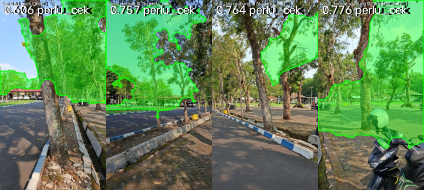

In [5]:
for k in pilih:
    rr = [r for r in belum if r["kelas"] == k][:8]
    if not rr:
        continue
    print(f"\n== {k}: {len(rr)} pertama dalam antrian ==")
    galeri = []
    for r in rr:
        ov = baca_gambar(D_SEG / "overlay" / k / (r["file"].rsplit(".", 1)[0] + ".jpg"))
        if ov is not None:
            galeri.append((ov, f"{r['skor']} {r['status']}"))
    if galeri:
        tampil_baris(galeri)

## 6. Tandai ROI (interaktif)

Untuk tiap gambar akan terbuka jendela OpenCV:

| Aksi | Tombol |
|---|---|
| Gambar kotak | seret mouse |
| Simpan | **ENTER** atau **SPASI** |
| Lewati / batal | **ESC** |

Jika tidak ada kotak, kolom input di bawah sel akan bertanya: **Enter = lewati, q = berhenti**. Setelah tiap gambar disimpan, hasilnya ditampilkan di notebook sebagai pratinjau. Hentikan kapan saja dengan tombol Stop/Interrupt; ROI yang sudah ditandai tetap tersimpan.

  [1/4] pohon_primer-pohon-32.jpg: ROI x=44 y=0 w=233 h=566 (total 667)


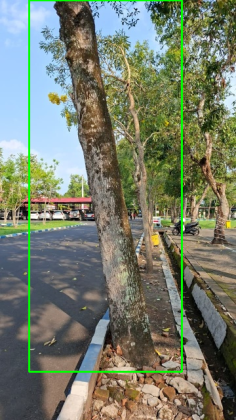

  [2/4] pohon_primer-pohon-34.jpg: ROI x=149 y=253 w=47 h=185 (total 668)


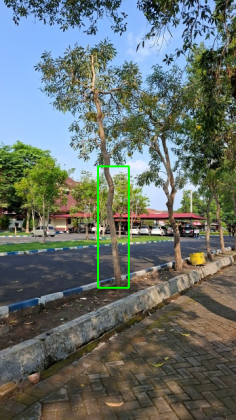

  [3/4] pohon_primer-pohon-33.jpg: ROI x=133 y=181 w=89 h=260 (total 669)


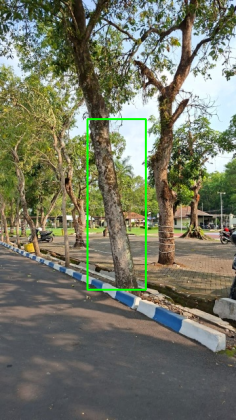

  [4/4] pohon_primer-pohon-35.jpg: ROI x=121 y=138 w=66 h=303 (total 670)


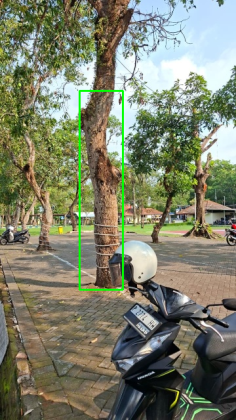


4 ROI baru ditandai. 670 ROI tersimpan di C:\Projek\vestcare-dataset\roi_manual.csv.


In [6]:
baru = 0
try:
    for i, r in enumerate(lap, 1):
        if r["file"] in roi:
            continue
        img = baca_gambar(D_CLEAN / "bersih" / r["kelas"] / r["file"])
        judul = f"[{i}/{len(lap)}] {r['kelas']} {r['file']}  ENTER=simpan  ESC=lewati/berhenti"
        try:
            x, y, w, h = cv2.selectROI(judul, img, showCrosshair=False)
        except cv2.error:
            print("Jendela OpenCV tidak tersedia di lingkungan ini. Pakai bagian 7 (isi koordinat lewat teks).")
            break
        tutup_jendela()
        if w == 0 or h == 0:
            j = input("  Tidak ada ROI. Enter = lewati, q = berhenti: ").strip().lower()
            if j == "q":
                break
            continue
        roi[r["file"]] = {"file": r["file"], "x": x, "y": y, "w": w, "h": h}
        simpan_roi(roi)
        baru += 1
        print(f"  [{i}/{len(lap)}] {r['file']}: ROI x={x} y={y} w={w} h={h} (total {len(roi)})")
        tampil(gambar_roi(img, x, y, w, h), 420)
except KeyboardInterrupt:
    print("\nDihentikan (Ctrl+C). ROI yang sudah ditandai tetap tersimpan.")
finally:
    tutup_jendela()
print(f"\n{baru} ROI baru ditandai. {len(roi)} ROI tersimpan di {ROI_CSV}.")

## 7. Alternatif tanpa jendela: isi ROI lewat koordinat

Untuk Colab / server tanpa layar, atau untuk memperbaiki satu gambar. Isi nama file dan koordinat `x, y, w, h` (piksel pada **gambar bersih**), lalu jalankan. Pratinjau kotak ditampilkan; kosongkan `DAFTAR_MANUAL` bila tidak dipakai.

In [7]:
# contoh: {"pohon_foto1.jpg": (40, 30, 300, 280)}
DAFTAR_MANUAL = {}

for nama, (x, y, w, h) in DAFTAR_MANUAL.items():
    baris = next((r for r in semua if r["file"] == nama), None)
    kelas = baris["kelas"] if baris else next((k for k in CLASSES if (D_CLEAN / "bersih" / k / nama).exists()), None)
    if kelas is None:
        print(f"  {nama}: tidak ditemukan di hasil/01_cleaning/bersih/, dilewati")
        continue
    img = baca_gambar(D_CLEAN / "bersih" / kelas / nama)
    H, W = img.shape[:2]
    if not (0 <= x < W and 0 <= y < H and w > 0 and h > 0 and x + w <= W and y + h <= H):
        print(f"  {nama}: kotak di luar gambar ({W}x{H}), dilewati")
        continue
    roi[nama] = {"file": nama, "x": x, "y": y, "w": w, "h": h}
    simpan_roi(roi)
    print(f"  {nama}: ROI x={x} y={y} w={w} h={h} disimpan")
    tampil(gambar_roi(img, x, y, w, h), 420)
if not DAFTAR_MANUAL:
    print("DAFTAR_MANUAL kosong, bagian ini dilewati.")

DAFTAR_MANUAL kosong, bagian ini dilewati.


## 8. Tinjau semua ROI tersimpan

Kotak hijau = ROI. Bila ada yang kurang pas, hapus barisnya di `roi_manual.csv` lalu ulangi bagian 4-6, atau timpa lewat bagian 7.

670 ROI di C:\Projek\vestcare-dataset\roi_manual.csv
ROI per kelas: {'pohon': 64, 'lubang': 186, 'orang': 70, 'motor': 196, 'mobil': 154}


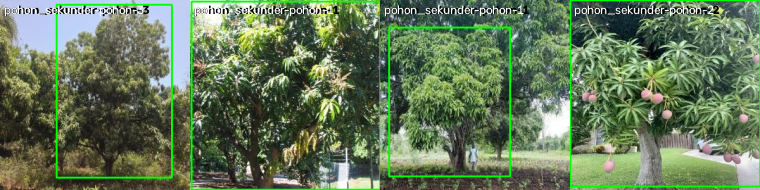

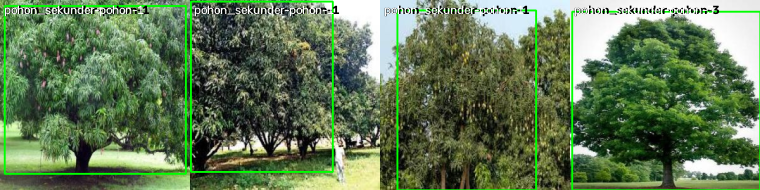

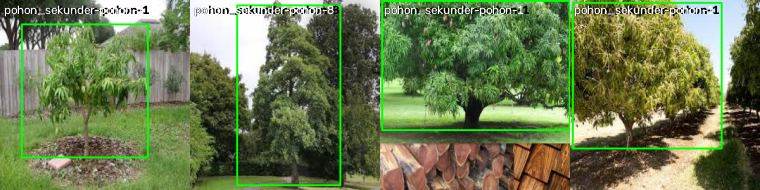

In [8]:
roi = {r["file"]: r for r in baca_csv(ROI_CSV)}
print(f"{len(roi)} ROI di {ROI_CSV}")
per_kelas = {}
galeri = []
for nama, r in roi.items():
    kelas = next((k for k in CLASSES if (D_CLEAN / "bersih" / k / nama).exists()), None)
    if kelas is None:
        continue
    per_kelas[kelas] = per_kelas.get(kelas, 0) + 1
    if len(galeri) < 12:
        im = baca_gambar(D_CLEAN / "bersih" / kelas / nama)
        galeri.append((gambar_roi(im, int(r["x"]), int(r["y"]), int(r["w"]), int(r["h"])), nama[:22]))
print("ROI per kelas:", per_kelas or "belum ada")
if galeri:
    tampil_baris(galeri)

## 9. Ringkasan dan langkah berikutnya

In [9]:
lap_semua = [r for r in baca_csv(D_SEG / "laporan_segmentasi.csv") if r["status"] in ("perlu_cek", "cadangan_roi")]
print(f"{'kelas':8s} {'perlu_cek':>10s} {'sudah ROI':>10s} {'belum ROI':>10s}")
for k in pilih:
    rr = [r for r in lap_semua if r["kelas"] == k]
    sudah = sum(r["file"] in roi for r in rr)
    print(f"{k:8s} {len(rr):10d} {sudah:10d} {len(rr) - sudah:10d}")
print(f"\n{len(roi)} ROI tersimpan di {ROI_CSV}")
if KELUARAN:
    print(f"Catatan: 02_segmentasi hanya membaca 'roi_manual.csv'. Salin/gabungkan {KELUARAN} ke roi_manual.csv sebelum menjalankannya.")
print("Langkah berikutnya: jalankan ulang notebook 02_segmentasi (opsional HALUSKAN = True), lalu 03_labelling.")

kelas     perlu_cek  sudah ROI  belum ROI
pohon             4          4          0
motor             0          0          0
mobil             0          0          0

670 ROI tersimpan di C:\Projek\vestcare-dataset\roi_manual.csv
Langkah berikutnya: jalankan ulang notebook 02_segmentasi (opsional HALUSKAN = True), lalu 03_labelling.
